
# Retinal Image Preprocessing

## Project: Retinopathy Detection System

### Objectives
1. Load original retinal images.
2. Remove unnecessary black borders.
3. Apply CLAHE contrast enhancement.
4. Experiment with Ben Graham preprocessing.
5. Compare original and processed images.
6. Prepare images for deep learning models.

### Dataset
APTOS 2019 Blindness Detection

### Preprocessing Techniques
- Retinal Cropping
- CLAHE Enhancement
- Ben Graham Preprocessing
- Image Resizing and Normalization


In [2]:

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image

# Dataset paths
BASE = Path("../data/raw/aptos/aptos2019-blindness-detection")
TRAIN_DIR = BASE / "train_images"
TEST_DIR = BASE / "test_images"

# Load training labels
train_df = pd.read_csv(BASE / "train.csv")

print("Dataset loaded successfully!")
print("Training records:", len(train_df))
print("Image folder exists:", TRAIN_DIR.exists())

display(train_df.head())


Dataset loaded successfully!
Training records: 3662
Image folder exists: True


,id_code,diagnosis
0,000c1434d8d7,2
1,001639a390f0,4
2,0024cdab0c1e,1
3,002c21358ce6,0
4,005b95c28852,0


Five sample retinal images loaded!


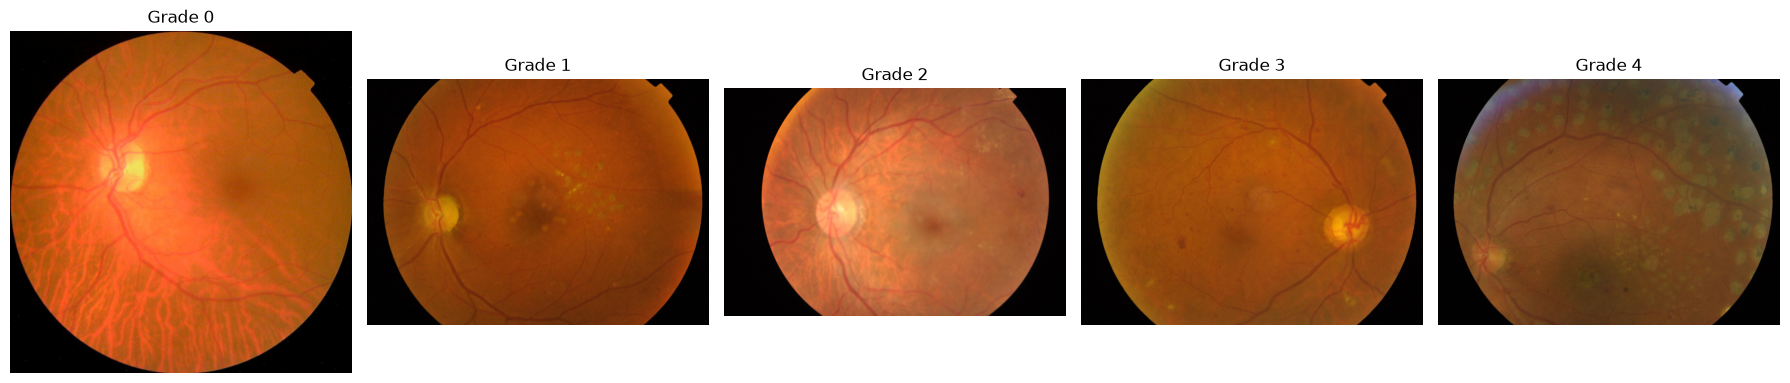

In [3]:

# Select one image from each grade
sample_images = {}

for grade in range(5):

    row = train_df[
        train_df["diagnosis"] == grade
    ].sample(n=1, random_state=42).iloc[0]

    image_path = TRAIN_DIR / (row["id_code"] + ".png")

    image = cv2.imread(str(image_path))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    sample_images[grade] = image

print("Five sample retinal images loaded!")

# Display images
fig, axes = plt.subplots(1, 5, figsize=(18, 5))

for grade, ax in enumerate(axes):
    ax.imshow(sample_images[grade])
    ax.set_title(f"Grade {grade}")
    ax.axis("off")

plt.tight_layout()
plt.show()


Original dimensions: (2136, 3216, 3)
Cropped dimensions: (2136, 2818, 3)


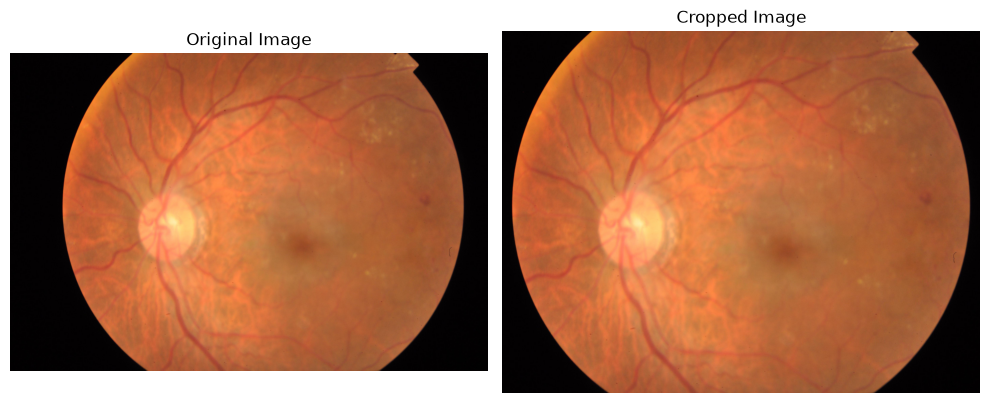

In [4]:

def crop_retina(image):

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Detect retinal region
    mask = gray > 10

    if not np.any(mask):
        return image

    coords = cv2.findNonZero(mask.astype(np.uint8))

    x, y, w, h = cv2.boundingRect(coords)

    # Add safety margin
    margin = int(max(w, h) * 0.02)

    x1 = max(0, x - margin)
    y1 = max(0, y - margin)

    x2 = min(image.shape[1], x + w + margin)
    y2 = min(image.shape[0], y + h + margin)

    return image[y1:y2, x1:x2]


# Test cropping
original = sample_images[2]
cropped = crop_retina(original)

print("Original dimensions:", original.shape)
print("Cropped dimensions:", cropped.shape)

# Display comparison
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cropped)
plt.title("Cropped Image")
plt.axis("off")

plt.tight_layout()
plt.show()


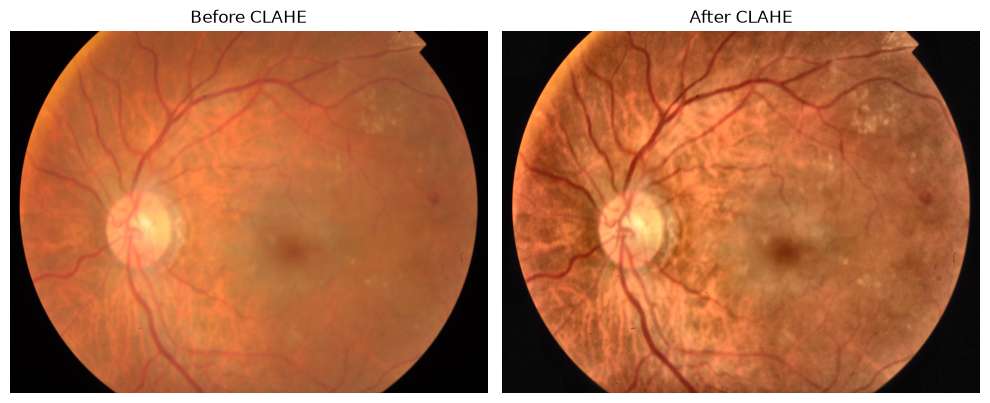

In [5]:

def apply_clahe(image):

    # Convert RGB to LAB
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)

    l, a, b = cv2.split(lab)

    # Apply CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced_l = clahe.apply(l)

    # Merge channels
    enhanced_lab = cv2.merge(
        (enhanced_l, a, b)
    )

    # Convert back to RGB
    return cv2.cvtColor(
        enhanced_lab,
        cv2.COLOR_LAB2RGB
    )


# Apply CLAHE
clahe_image = apply_clahe(cropped)

# Display comparison
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cropped)
plt.title("Before CLAHE")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clahe_image)
plt.title("After CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()


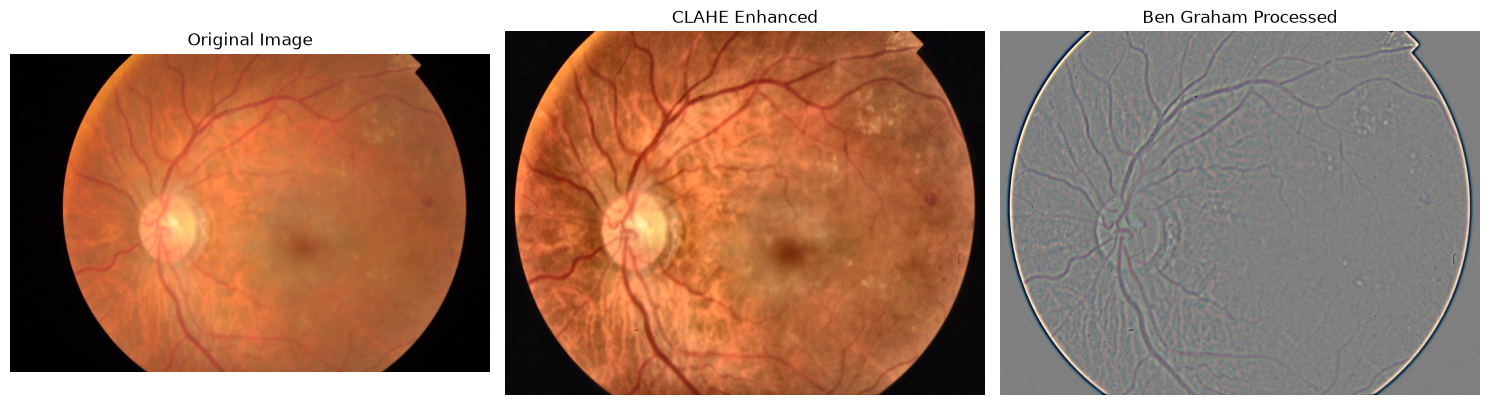

In [6]:

def ben_graham(image, sigma=10, scale=4, offset=128):

    blurred = cv2.GaussianBlur(
        image,
        (0, 0),
        sigma
    )

    processed = cv2.addWeighted(
        image,
        scale,
        blurred,
        -scale,
        offset
    )

    return processed


# Apply Ben Graham preprocessing
ben_image = ben_graham(cropped)

# Compare three images
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(clahe_image)
plt.title("CLAHE Enhanced")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(ben_image)
plt.title("Ben Graham Processed")
plt.axis("off")

plt.tight_layout()
plt.show()


EfficientNetB3 shape: (300, 300, 3)
MobileNetV2 shape: (224, 224, 3)
Normalized pixel range: 0.011764706 to 1.0


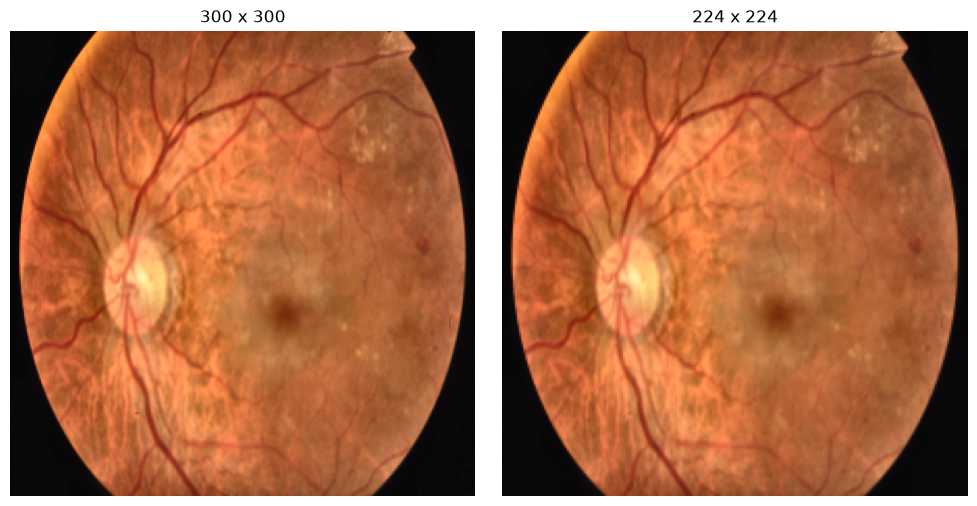

In [7]:

def resize_image(image, size=(300, 300)):

    return cv2.resize(
        image,
        size,
        interpolation=cv2.INTER_AREA
    )


# Resize processed image
efficientnet_image = resize_image(
    clahe_image, (300, 300)
)

mobilenet_image = resize_image(
    clahe_image, (224, 224)
)

# Normalize pixel values for inspection
efficientnet_normalized = (
    efficientnet_image.astype(np.float32) / 255.0
)

mobilenet_normalized = (
    mobilenet_image.astype(np.float32) / 255.0
)

print("EfficientNetB3 shape:", efficientnet_image.shape)
print("MobileNetV2 shape:", mobilenet_image.shape)

print(
    "Normalized pixel range:",
    efficientnet_normalized.min(),
    "to",
    efficientnet_normalized.max()
)

# Display resized images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(efficientnet_image)
plt.title("300 x 300")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(mobilenet_image)
plt.title("224 x 224")
plt.axis("off")

plt.tight_layout()
plt.show()



## Conclusion

In this experiment, retinal image preprocessing
techniques were explored.

The following techniques were implemented:

1. Retinal Image Loading
2. Retinal Cropping
3. CLAHE Contrast Enhancement
4. Ben Graham Preprocessing
5. Image Resizing
6. Pixel Normalization

The processed images will be evaluated before
selecting the final preprocessing pipeline for
deep learning model development.

### Future Work
- Data Augmentation
- EfficientNetB3 Model Training
- MobileNetV2 Model Training
- Hybrid Feature Fusion Model
- Model Evaluation and Comparison
